# Assignment 2 — Data Preparation & Baseline
## Predicting failed public-procurement contracts in Kazakhstan

**Author:** Aziz Abdulin · **Course project:** Tender Risk ML · **Repository:** https://github.com/awzwz/tender-risk-ml

This notebook takes the raw open-data snapshot of the Kazakhstan public procurement portal and turns it into a clean,
leakage-safe modelling table with a time-based train / validation / test split, followed by a first baseline model.
It is organised in the order of the assessment criteria:

| § | Criterion |
|---|---|
| 1 | Dataset selection and description |
| 2 | Research problem, research questions, hypotheses |
| 3 | Data loading & reproducibility |
| 4 | Data structure examination |
| 5 | Data quality assessment |
| 6 | Data cleaning (before → after) |
| 7–8 | Exploratory data analysis and visualisation |
| 9 | Features, target, data-leakage audit |
| 10 | Train / validation / test split |
| 11 | Baseline model |
| 12 | Scientific interpretation and conclusions |

**How to run:** `Kernel → Restart & Run All`. The notebook finds the repository root by itself and downloads the data
snapshot (≈400 MB, GitHub release `data-v1`) on first run if `data/raw/` is empty. Full run ≈ 1–2 minutes.
On Google Colab, run the commented cell in §3 first.

## 1. Dataset selection and description

| | |
|---|---|
| **Source** | OWS v3 GraphQL API of the Kazakhstan public procurement portal — the official open-data interface of goszakup.gov.kz, operated by the Ministry of Finance of the Republic of Kazakhstan. API: https://ows.goszakup.gov.kz · portal: https://goszakup.gov.kz |
| **Domain** | Public procurement (government purchasing of goods, works and services) |
| **Origin** | Administrative records created by the e-procurement system itself: every announcement, lot, supplier application and contract is registered electronically by the portal. Not a survey, not synthetic. |
| **Collection** | Collected by the author between 12 September and 6 October 2026 with `src/collect.py` (resumable cursor pagination over the API, personal API token). Raw snapshot is published as GitHub release `data-v1` so the analysis is reproducible without a token. |
| **Period** | All procurements **published 1 January – 31 March 2024** and every record linked to them (lots, applications, contracts), plus the full register of unreliable suppliers (RNU) as of October 2026. |
| **Size** | 5 linked tables, ≈3.6 million rows, 400 MB in Parquet (details in §4). |
| **Purpose of the dataset** | Transparency of state spending: the portal publishes it so that citizens, auditors and journalists can monitor procurement. |

**Why this dataset fits the task.** The research task (§2) needs (a) a large number of independent purchasing decisions,
(b) information available *before* the contract is executed, and (c) an *observed outcome* of the contract.
This dataset provides all three: hundreds of thousands of procurements, their attributes and competition at award time,
and the final legal status of every contract (executed / terminated / not concluded). Q1 2024 was chosen deliberately:
by October 2026 every contract from that quarter has had more than two years to reach its final status, so the
outcome label is settled rather than "still in progress".

## 2. Research problem

**Problem.** Kazakhstan's procurement portal handles ≈1.8 million procurements per year. A noticeable share of the
resulting contracts are terminated or never signed, which means repeated procedures, delayed goods and services and
wasted budget. Control bodies can inspect only a tiny fraction of procurements by hand, so they need a way to tell
*in advance* which procurements are likely to end badly.

**Research aim.** To determine which characteristics of a procurement, known at the moment the winner is selected, are
associated with the failure of the resulting contract, and whether these characteristics allow failures to be
predicted on a later time period.

**Research questions and hypotheses**

| | Research question | Hypothesis |
|---|---|---|
| **RQ1** | How are the procurement method and the level of competition (number of bidders) related to the probability that the contract fails? | **H1:** within the same procurement method, single-bidder procurements fail more often than procurements with moderate competition (2–3 bidders). |
| **RQ2** | Is the failure probability associated with the size, type and location of the purchase (value; goods / works / services; region)? | **H2:** the failure probability increases with the procurement value. |
| **RQ3** | Can information available at award time separate failing from successful contracts substantially better than chance on a *later* period? | **H3:** a simple linear baseline trained on January–February 2024 reaches ROC-AUC well above 0.5 and a PR-AUC several times above the base rate on March 2024. |

The outcome studied (target) is `contract_failed` — whether the contract that resulted from the procurement was
terminated or not concluded (exact definition in §9).

## 3. Data loading & reproducibility

In [1]:
# Google Colab only: uncomment and run this cell first.
# !git clone -q https://github.com/awzwz/tender-risk-ml && pip -q install duckdb
# import os; os.chdir("tender-risk-ml/notebooks")

In [2]:
import sys, urllib.request, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# locate the repository root no matter where the notebook is started from
ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src import prepare as P

RAW = ROOT / "data" / "raw"
FIG = ROOT / "figures"
PROCESSED = ROOT / "data" / "processed"
for d in (RAW, FIG, PROCESSED):
    d.mkdir(parents=True, exist_ok=True)

RELEASE_URL = "https://github.com/awzwz/tender-risk-ml/releases/download/data-v1/"
for t in P.TABLES:
    f = RAW / f"{t}.parquet"
    if not f.exists():
        print(f"downloading {f.name} ...")
        urllib.request.urlretrieve(RELEASE_URL + f.name, f)

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"ok": "#2b6cb0", "fail": "#c53030", "grey": "#a0aec0"}
print("repository root:", ROOT)
print({t: f"{(RAW / f'{t}.parquet').stat().st_size / 1e6:.1f} MB" for t in P.TABLES})

repository root: /Users/awz_wz/Projects/tender-risk-ml
{'trd_buy': '125.7 MB', 'lots': '122.8 MB', 'contracts': '58.0 MB', 'trd_app': '88.8 MB', 'rnu': '0.8 MB'}


In [3]:
# DuckDB reads the Parquet files directly (SQL over files, no database server needed).
con = P.connect(RAW)
raw = {t: con.sql(f"SELECT * FROM {t}_raw").df() for t in P.TABLES}
pd.DataFrame({t: {"rows": len(df), "columns": df.shape[1]} for t, df in raw.items()}).T

,rows,columns
trd_buy,630762,37
lots,1286364,30
contracts,555723,36
trd_app,1066963,10
rnu,17343,8


All five tables load without errors. They are linked like tables of a relational database:

* `trd_buy.id` ← `lots.trdBuyId`, `contracts.trdBuyId`, `trd_app.buyId` (procurement id is the foreign key);
* `rnu.supplierBiin` ↔ `contracts.supplierBiin` (BIN — the business identification number of a company).

## 4. Data structure examination
### 4.1 Shape, column names and types

In [4]:
for t, df in raw.items():
    print(f"=== {t}: {df.shape[0]:,} rows × {df.shape[1]} columns")
    print(", ".join(f"{c} ({str(df[c].dtype)})" for c in df.columns), "\n")

=== trd_buy: 630,762 rows × 37 columns
id (int64), numberAnno (str), nameRu (str), nameKz (str), refTradeMethodsId (int64), refSubjectTypeId (int64), refBuyStatusId (int64), refTypeTradeId (int64), refSpecPurchaseTypeId (int64), publishDate (str), startDate (str), endDate (str), repeatStartDate (str), repeatEndDate (str), itogiDatePublic (str), totalSum (float64), countLots (int64), orgBin (str), orgPid (int64), orgNameRu (str), customerBin (Int32), customerPid (int64), customerNameRu (Int32), idSupplier (int64), biinSupplier (str), singlOrgSign (int64), isLightIndustry (int64), isConstructionWork (int64), disablePersonId (int64), parentId (int64), finYear (str), kato (str), systemId (int64), lastUpdateDate (str), indexDate (str), RefBuyStatus_nameRu (str), RefTradeMethods_nameRu (str) 

=== lots: 1,286,364 rows × 30 columns
id (int64), trdBuyId (int64), trdBuyNumberAnno (str), lotNumber (str), nameRu (str), nameKz (str), descriptionRu (str), amount (float64), count (float64), customer

In [5]:
raw["trd_buy"].info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 630762 entries, 0 to 630761
Data columns (total 37 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   id                      630762 non-null  int64  
 1   numberAnno              630762 non-null  str    
 2   nameRu                  630762 non-null  str    
 3   nameKz                  630762 non-null  str    
 4   refTradeMethodsId       630762 non-null  int64  
 5   refSubjectTypeId        630762 non-null  int64  
 6   refBuyStatusId          630762 non-null  int64  
 7   refTypeTradeId          630762 non-null  int64  
 8   refSpecPurchaseTypeId   630762 non-null  int64  
 9   publishDate             630762 non-null  str    
 10  startDate               630762 non-null  str    
 11  endDate                 630762 non-null  str    
 12  repeatStartDate         13515 non-null   str    
 13  repeatEndDate           13515 non-null   str    
 14  itogiDatePublic         623730 

In [6]:
raw["trd_buy"].head(3).T

,0,1,2
id,12573110,12448000,12299140
numberAnno,12030702-2,11393753-4,11737769-2
nameRu,Разработка ПСД на установки уличного освещения...,Конкурстық құжаттамаға сәйкес мемлекеттік саты...,Содержание скверов Турксибского района для КГУ...
nameKz,Алматы облысы Райымбек ауданының ауылдарына к...,Закупка согласно конкурсной документаций,"""Алматы қаласы Түрксіб ауданы әкімінің аппарат..."
refTradeMethodsId,188,2,2
refSubjectTypeId,2,2,3
refBuyStatusId,430,430,430
refTypeTradeId,60,3,3
refSpecPurchaseTypeId,0,0,0
publishDate,2024-03-29 15:32:07,2024-03-18 22:11:01,2024-02-20 13:59:18


### 4.2 Descriptive statistics

In [7]:
raw["trd_buy"][["totalSum", "countLots"]].describe(percentiles=[.01, .25, .5, .75, .99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
totalSum,"630,762.0000","7,776,971.1517","241,303,311.9491",0.0000,"2,833.9261","71,428.5700","240,000.0000","832,000.0000","86,477,210.0000","79,843,399,986.5000"
countLots,"630,762.0000",2.0269,4.8894,0.0000,1.0000,1.0000,1.0000,1.0000,22.0000,294.0000


In [8]:
pd.concat({
    "lots.amount": raw["lots"]["amount"].describe(percentiles=[.01, .5, .99]),
    "lots.count": raw["lots"]["count"].describe(percentiles=[.01, .5, .99]),
    "contracts.contractSum": raw["contracts"]["contractSum"].describe(percentiles=[.01, .5, .99]),
}, axis=1).T

,count,mean,std,min,1%,50%,99%,max
lots.amount,"1,286,364.0000","3,817,879.3746","121,859,355.4555",0.0000,448.0000,"74,890.0000","38,000,000.0000","51,785,873,620.0000"
lots.count,"1,286,364.0000","2,766.2071","161,918.7812",0.0000,1.0000,3.0000,"29,129.0000","78,547,429.0000"
contracts.contractSum,"555,723.0000","13,947,413.5469","234,491,141.5134",0.0100,"2,850.0000","144,000.0000","214,648,195.5800","37,080,475,538.2600"


In [9]:
cat_cols = {"trd_buy": ["RefTradeMethods_nameRu", "RefBuyStatus_nameRu", "refSubjectTypeId"],
            "contracts": ["RefContractStatus_nameRu"], "lots": ["RefLotsStatus_nameRu"]}
for t, cols in cat_cols.items():
    for c in cols:
        vc = raw[t][c].value_counts(dropna=False)
        print(f"{t}.{c}: {vc.size} categories; top-5 share:")
        print((vc.head(5) / len(raw[t]) * 100).round(2).to_string(), "\n")

trd_buy.RefTradeMethods_nameRu: 17 categories; top-5 share:
RefTradeMethods_nameRu
Запрос ценовых предложений                                   62.9300
Из одного источника по несостоявшимся закупкам               22.0600
Второй этап конкурса с использованием рамочного соглашения    6.0800
Открытый конкурс                                              4.5600
Конкурс с предварительным квалификационным отбором            1.2000 

trd_buy.RefBuyStatus_nameRu: 10 categories; top-5 share:
RefBuyStatus_nameRu
Завершено                       96.2400
Отменено                         1.9100
Изменена документация            1.0200
Отказ от закупки                 0.8000
Формирование протокола итогов    0.0200 

trd_buy.refSubjectTypeId: 3 categories; top-5 share:
refSubjectTypeId
3   49.6800
1   42.4600
2    7.8500 

contracts.RefContractStatus_nameRu: 15 categories; top-5 share:
RefContractStatus_nameRu
Исполнен                             77.5800
Изменен                              13.9600
Раст

### 4.3 What the important columns mean

| Table | Column | Meaning |
|---|---|---|
| `trd_buy` | `id`, `numberAnno` | technical id and public announcement number of the procurement |
| | `RefTradeMethods_nameRu` | procurement method: request for quotations, open tender, single source after a failed tender, framework agreement, … |
| | `refSubjectTypeId` | subject of the purchase: 1 = goods, 2 = works, 3 = services |
| | `totalSum` | planned value of the procurement, KZT |
| | `countLots` | number of lots in the announcement |
| | `publishDate`, `startDate`, `endDate` | publication date and the window during which suppliers may submit applications |
| | `kato` | location code (KATO classifier); its first two digits are the region |
| | `orgBin` | BIN of the organiser (the buying institution) |
| | `parentId` | link to an earlier procurement (set mostly for single-source purchases after a failed tender) |
| | `singlOrgSign`, `isConstructionWork`, `isLightIndustry`, `disablePersonId` | flags: single organiser, construction works, light industry, organisations of disabled people |
| `lots` | `amount`, `count` | planned total value and quantity of the lot |
| | `nameRu`, `descriptionRu` | catalogue name and description of what is bought (text) |
| | `dumping` | anti-dumping provisions apply to the lot (tenders only) |
| `trd_app` | `buyId`, `supplierBinIin` | which supplier applied to which procurement |
| | `AppLots` | JSON list of per-lot offers: lot id, **unit** price, status |
| `contracts` | `rootId`, `parentId` | a contract and all its amendments share the same `rootId` |
| | `refContractStatusId` / `RefContractStatus_nameRu` | legal status: executed, partially executed, terminated (unilaterally / by agreement), not concluded, amended, … — **source of the target** |
| | `contractSum`, `faktSum`, `faktExecDate` | contract value and *actual* execution — only known after execution |
| `rnu` | `supplierBiin`, `startDate`, `endDate` | supplier and period of inclusion in the register of unreliable suppliers |

## 5. Data quality assessment
### 5.1 Missing values

In [10]:
miss = []
for t, df in raw.items():
    m = df.isna().mean() * 100
    for c, v in m[m > 0].items():
        miss.append({"table": t, "column": c, "missing_%": round(v, 2), "missing_n": int(df[c].isna().sum())})
miss = pd.DataFrame(miss).sort_values(["table", "missing_%"], ascending=[True, False])
miss

,table,column,missing_%,missing_n
11,contracts,RefContractCancel,100.0000,555723
12,contracts,RefContractCancel_nameRu,97.7200,543065
9,contracts,contractEndDate,95.8100,532437
8,contracts,faktExecDate,22.0300,122426
6,contracts,signDate,1.4800,8222
7,contracts,planExecDate,0.2300,1278
10,contracts,trdBuyItogiDatePublic,0.0000,22
14,rnu,supplierBiin,0.0100,1
13,trd_app,AppLots,0.0200,181
3,trd_buy,customerBin,100.0000,630762


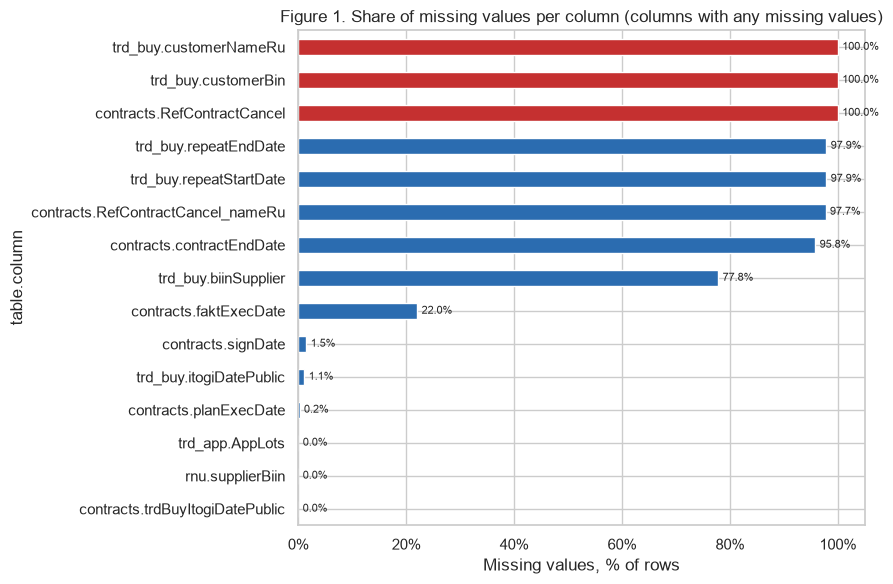

In [11]:
fig, ax = plt.subplots(figsize=(9, 6))
m = miss.assign(label=miss.table + "." + miss.column).set_index("label")["missing_%"].sort_values()
m.plot.barh(ax=ax, color=[PALETTE["fail"] if v == 100 else PALETTE["ok"] for v in m])
ax.set_title("Figure 1. Share of missing values per column (columns with any missing values)")
ax.set_xlabel("Missing values, % of rows")
ax.set_ylabel("table.column")
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
for i, v in enumerate(m):
    ax.text(v + 0.8, i, f"{v:.1f}%", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "fig01_missing.png", dpi=150); plt.show()

**Interpretation (Figure 1).** Missingness is concentrated in a few columns and is mostly *structural*, not random:

* `trd_buy.customerBin` and `trd_buy.customerNameRu` are **100 % empty** — the API never fills them for this entity
  (the customer is identified through `orgBin` and the lots instead). They carry no information and will be dropped.
* `trd_buy.biinSupplier` / `idSupplier` (winner) are missing for ≈78 % of procurements — the winner is reliably
  recorded only in `contracts`, so we take it from there.
* `repeatStartDate/repeatEndDate` exist only for repeated procedures — missing means "not repeated".
* `contracts.RefContractCancel` (the id of the nested cancellation object) is also 100 % empty; its readable
  counterpart `RefContractCancel_nameRu` is filled only for the 2.3 % of contracts that were cancelled.
* `contracts.signDate` is missing for 8.2 thousand rows (1.5 %); ≈ 7.5 thousand of them have the status
  *Not concluded* — the contract was never signed, so the gap is expected and confirms the status.
* `contracts.faktExecDate` (actual execution date) is missing for 22 % of rows — contracts that were not (fully)
  executed — and `contractEndDate` is almost never filled (96 %); both describe the outcome and are not used as features.
* `trd_app.AppLots` is missing for 181 applications (0.02 %) — applications without any lot offer.

### 5.2 Duplicates

In [12]:
dups = pd.DataFrame([
    {"check": "trd_buy: duplicate id", "n": raw["trd_buy"]["id"].duplicated().sum()},
    {"check": "trd_buy: duplicate announcement number", "n": raw["trd_buy"]["numberAnno"].duplicated().sum()},
    {"check": "lots: duplicate id", "n": raw["lots"]["id"].duplicated().sum()},
    {"check": "lots: duplicate (procurement, lot number)", "n": raw["lots"].duplicated(["trdBuyId", "lotNumber"]).sum()},
    {"check": "trd_app: duplicate id", "n": raw["trd_app"]["id"].duplicated().sum()},
    {"check": "contracts: duplicate id", "n": raw["contracts"]["id"].duplicated().sum()},
    {"check": "contracts: extra versions of the same contract (same rootId)", "n": raw["contracts"]["rootId"].duplicated().sum()},
    {"check": "rnu: duplicate supplier BIN", "n": raw["rnu"]["supplierBiin"].duplicated().sum()},
])
dups["% of table"] = [round(r.n / len(raw[r.check.split(":")[0]]) * 100, 3) for r in dups.itertuples()]
dups

,check,n,% of table
0,trd_buy: duplicate id,0,0.0000
1,trd_buy: duplicate announcement number,0,0.0000
2,lots: duplicate id,0,0.0000
3,"lots: duplicate (procurement, lot number)",0,0.0000
4,trd_app: duplicate id,0,0.0000
5,contracts: duplicate id,0,0.0000
6,contracts: extra versions of the same contract...,75454,13.5780
7,rnu: duplicate supplier BIN,0,0.0000


There are **no exact duplicates of records** (every id is unique, business keys are unique). The one real
duplication problem is semantic: **75,454 contract rows (13.6 %) are amendments** — additional versions of an
already existing contract that share its `rootId`. Treating them as separate contracts would count the same
contract several times with different statuses; they are collapsed in §6. The only other anomaly is one RNU record
without a supplier BIN.

### 5.3 Incorrect values, wrong types, inconsistent categories, referential integrity

In [13]:
tb, ct, lt = raw["trd_buy"], raw["contracts"], raw["lots"]
issues = pd.DataFrame([
    {"issue": "totalSum ≤ 0 (a procurement must have a positive value)", "n": int((tb.totalSum <= 0).sum()), "base": len(tb)},
    {"issue": "dates stored as text (publishDate, startDate, …)", "n": len(tb), "base": len(tb)},
    {"issue": "kato / finYear stored as JSON text, e.g. '[\"195830100\"]', '[2024]'", "n": len(tb), "base": len(tb)},
    {"issue": "kato missing ('[null]')", "n": int((tb.kato == "[null]").sum()), "base": len(tb)},
    {"issue": "isConstructionWork is a 0/1 flag but takes values 2, 3, 4", "n": int((tb.isConstructionWork > 1).sum()), "base": len(tb)},
    {"issue": "endDate earlier than startDate", "n": int((tb.endDate < tb.startDate).sum()), "base": len(tb)},
    {"issue": "lots.amount ≤ 0", "n": int((lt.amount <= 0).sum()), "base": len(lt)},
    {"issue": "lots without a parent procurement (orphans)", "n": int((~lt.trdBuyId.isin(tb.id)).sum()), "base": len(lt)},
    {"issue": "contracts without a parent procurement (orphans)", "n": int((~ct.trdBuyId.isin(tb.id)).sum()), "base": len(ct)},
    {"issue": "cancel reasons with '§' prefix / trailing newline (inconsistent strings)",
     "n": int(ct.RefContractCancel_nameRu.fillna("").str.contains("§|\n").sum()), "base": len(ct)},
])
issues["%"] = (issues.n / issues.base * 100).round(3)
issues

,issue,n,base,%
0,totalSum ≤ 0 (a procurement must have a positi...,1913,630762,0.3030
1,"dates stored as text (publishDate, startDate, …)",630762,630762,100.0000
2,"kato / finYear stored as JSON text, e.g. '[""19...",630762,630762,100.0000
3,kato missing ('[null]'),1976,630762,0.3130
4,isConstructionWork is a 0/1 flag but takes val...,3968,630762,0.6290
5,endDate earlier than startDate,0,630762,0.0000
6,lots.amount ≤ 0,4842,1286364,0.3760
7,lots without a parent procurement (orphans),0,1286364,0.0000
8,contracts without a parent procurement (orphans),0,555723,0.0000
9,cancel reasons with '§' prefix / trailing newl...,12658,555723,2.2780


In [14]:
print("Procurement methods as published (17 categories, long tail):")
print((tb.RefTradeMethods_nameRu.value_counts() / len(tb) * 100).round(2).to_string())

Procurement methods as published (17 categories, long tail):
RefTradeMethods_nameRu
Запрос ценовых предложений                                                                      62.9300
Из одного источника по несостоявшимся закупкам                                                  22.0600
Второй этап конкурса с использованием рамочного соглашения                                       6.0800
Открытый конкурс                                                                                 4.5600
Конкурс с предварительным квалификационным отбором                                               1.2000
Конкурс с использованием рейтингово-балльной системы                                             0.9400
Конкурс по приобретению товаров, связанных с обеспечением питания воспитанников и обучающихся    0.7900
Закупка по государственному социальному заказу                                                   0.3100
Государственные закупки с применением особого порядка                               

Category labels are consistent in spelling, but the method variable has a **long tail**: 17 methods, of which
10 cover less than 0.5 % of procurements each, and several are near-duplicates by meaning
(*"Request for quotations"* vs *"Request for quotations (non-GZ new)"*; *"Single source after failed tenders"* vs the
same with *"non-GZ"*). Rare methods will be grouped into **Other** so that each category has enough observations.

### 5.4 Outliers

In [15]:
s = tb.loc[tb.totalSum > 0, "totalSum"]
q1, q3 = np.log10(s).quantile([.25, .75]); iqr = q3 - q1
out_hi = (np.log10(s) > q3 + 1.5 * iqr).sum(); out_lo = (np.log10(s) < q1 - 1.5 * iqr).sum()
print(f"totalSum: median {s.median():,.0f} KZT, max {s.max():,.0f} KZT; skewness {s.skew():.1f}")
print(f"IQR rule on log10 scale: {out_hi:,} high and {out_lo:,} low outliers ({(out_hi + out_lo) / len(s):.2%})")

# bid price relative to the planned unit price of the lot (computed after unnesting AppLots in §6)
P.build_clean_tables(con)
ratio = con.sql('''
    SELECT b.price * l.count / l.amount AS r
    FROM clean_bid b JOIN lots_raw l ON l.id = b.lot_id
    WHERE b.price > 0 AND l.amount > 0 AND l.count > 0''').df().r
print(f"\nbid / planned unit price: median {ratio.median():.3f}; "
      f"> 1 (bid above planned price): {(ratio > 1.0001).mean():.2%}; "
      f"< 0.05 (95 %+ below plan, implausible): {(ratio < .05).mean():.2%}; max {ratio.max():,.1f}")

totalSum: median 242,589 KZT, max 79,843,399,986 KZT; skewness 210.9
IQR rule on log10 scale: 12,967 high and 2,214 low outliers (2.41%)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


bid / planned unit price: median 0.791; > 1 (bid above planned price): 0.58%; < 0.05 (95 %+ below plan, implausible): 0.56%; max 100.0


* **Procurement value is extremely right-skewed** (median ≈ 240 thousand KZT, maximum ≈ 80 billion KZT). The large
  values are real (construction, infrastructure), not errors, so they are **kept** and modelled on a log scale.
* **Bid-to-plan price ratio:** by law an offer may not exceed the planned price, yet a small share of offers are
  above it, and some are 20× below it. These are unit-of-measure inconsistencies (e.g. the price entered per package
  while the plan is per item), so ratios outside **[0.05, 1.0]** are treated as invalid in §6.

### 5.5 Coverage of the RNU register (important for leakage)

In [16]:
r = raw["rnu"]
print("RNU inclusions by start year:", r.startDate.str[:4].value_counts().sort_index().to_dict())
print("RNU entries already active on 2024-01-01:", int(((r.startDate < "2024-01-01") & (r.endDate > "2024-01-01")).sum()))

RNU inclusions by start year: {'2024': 2707, '2025': 8682, '2026': 5954}
RNU entries already active on 2024-01-01: 0


The register only contains **current** entries (inclusions start in 2024–2026 and last two years; expired entries are
removed by the portal). No supplier was in the register *before* our procurements, while many were added *after*
them — very likely **because** of the terminated contracts we want to predict. RNU therefore cannot be used as a
feature (it would leak the outcome); it is kept only for descriptive analysis.

### 5.6 Summary of data quality

| Problem | Extent | Treatment (§6) |
|---|---|---|
| Fully empty columns | 3 (`customerBin`, `customerNameRu` in `trd_buy`; `RefContractCancel` in `contracts`) | drop / not selected |
| Wrong types (dates, JSON lists as text) | all rows | convert |
| Contract amendments counted as separate rows | 75,454 rows (13.6 %) | collapse to final version per `rootId` |
| Non-positive procurement value | 1,913 procurements (0.30 %) | excluded (none of them produced a contract) |
| Mis-coded flag `isConstructionWork` (0–4) | 3,968 procurements (0.63 %) | binarise (>0) |
| Non-positive lot value `lots.amount` | 4,842 lots (0.38 %) | excluded from price-ratio calculation |
| Long-tail categories | 17 methods, 10 below 0.5 % | group into 8 |
| Implausible bid/plan price ratios | ≈ 1.1 % of priced offers (2.1 % of procurements) | set to missing |
| Skewed values / outliers | totalSum skewness ≈ 211; 2.4 % IQR outliers on log scale | keep, log-transform |
| Structural missingness | winner, repeat dates, signDate | explained; winner taken from contracts |

## 6. Data cleaning

Each step below states **what** is changed, **why**, and shows the data **before → after**.
The SQL of every step lives in `src/prepare.py` (`build_clean_tables`, `build_model_table`) so the midterm notebook
reuses exactly the same cleaning.

In [17]:
log = []
def step(name, before, after, why):
    log.append({"step": name, "before": before, "after": after, "why": why})

# C1 — drop fully empty columns
empty_cols = [c for c in raw["trd_buy"].columns if raw["trd_buy"][c].isna().all()]
step("C1 drop 100 %-empty columns of trd_buy", f"{raw['trd_buy'].shape[1]} columns",
     f"{raw['trd_buy'].shape[1] - len(empty_cols)} columns", f"{empty_cols} carry no information")

# C2 — types: dates -> TIMESTAMP, kato JSON -> region, codes -> readable labels (done in SQL)
buy = con.sql("SELECT * FROM clean_buy").df()
step("C2 convert types & decode codes", "dates as text; kato '[\"195830100\"]'",
     f"publish_dt {buy.publish_dt.dtype}; region e.g. '{buy.region.iloc[0]}'",
     "text dates cannot be compared or differenced; codes are unreadable")
print(buy[["publish_dt", "start_dt", "end_dt", "region", "subject_type", "trade_method"]].dtypes)
buy[["id", "publish_dt", "region", "subject_type", "trade_method"]].head(3)

publish_dt      datetime64[us]
start_dt        datetime64[us]
end_dt          datetime64[us]
region                     str
subject_type               str
trade_method               str
dtype: object


,id,publish_dt,region,subject_type,trade_method
0,12573110,2024-03-29 15:32:07,Almaty region,Works,Tender with scoring system
1,12448000,2024-03-18 22:11:01,Turkestan,Works,Open tender
2,12299140,2024-02-20 13:59:18,Almaty city,Services,Open tender


In [18]:
# C3 — contract amendments -> one row per contract chain (the last version holds the final status)
chains = con.sql("SELECT * FROM clean_contract").df()
step("C3 collapse contract amendments", f"{len(raw['contracts']):,} contract rows",
     f"{len(chains):,} contracts", "an amendment is a new version of the same contract, not a new contract")

before = raw["contracts"].RefContractStatus_nameRu.value_counts().head(6)
after = chains.status_ru.value_counts().head(6)
pd.concat({"rows before": before, "contracts after": after}, axis=1).fillna(0).astype(int)

,rows before,contracts after
Исполнен,431124,430931
Изменен,77569,4006
Расторгнут в одностороннем порядке,13584,13562
Частично исполнен,12904,12826
Расторгнут по соглашению сторон,8434,8434
Не заключен,7724,7539


Before collapsing, *Amended* (Изменен) looks like the second most frequent status (77.6 thousand rows); after taking
the last version of each chain only 4 thousand contracts remain in that state — almost all amended contracts in fact
ended up *Executed*. Without this step the target would have been badly distorted.

In [19]:
# C4 — modelling population and target (one row per procurement with at least one contract)
df = P.build_model_table(con)
no_contract = len(buy) - len(df)
step("C4 keep procurements that produced a contract", f"{len(buy):,} procurements", f"{len(df):,} procurements",
     f"{no_contract:,} procurements ({no_contract / len(buy):.1%}) have no contract — no outcome to predict "
     "(cancelled or failed tenders are a different problem)")
print("non-positive totalSum inside the population:", int((df.total_sum <= 0).sum()),
      "| outside:", int((buy.total_sum <= 0).sum()))

non-positive totalSum inside the population: 0 | outside: 1913


In [20]:
# C5 — mis-coded flag, C6 — rare categories, C7 — invalid price ratios
n_constr = int((df.construction > 1).sum())
df["construction"] = (df.construction > 0).astype(int)
step("C5 binarise isConstructionWork", "values {0,1,2,3,4}", "values {0,1}",
     f"{n_constr:,} rows used codes 2–4 for 'yes'; the field is a flag")

step("C6 group rare procurement methods", f"{buy.trade_method_ru.nunique()} categories",
     f"{df.trade_method.nunique()} categories", "methods below ~1 % share merged into 'Other' (enough data per level)")

bad_ratio = df.best_bid_ratio.notna() & ~df.best_bid_ratio.between(0.05, 1.0001)
step("C7 invalid bid/plan price ratio -> missing", f"{df.best_bid_ratio.notna().sum():,} values",
     f"{(df.best_bid_ratio.notna() & ~bad_ratio).sum():,} values",
     f"{int(bad_ratio.sum()):,} ratios outside [0.05, 1] are unit-of-measure errors")
df.loc[bad_ratio, "best_bid_ratio"] = np.nan

# C8 — skewed value kept, log-transformed feature added
df["log_total_sum"] = np.log10(df.total_sum)
step("C8 log-transform procurement value", f"skewness {df.total_sum.skew():.1f}",
     f"skewness {df.log_total_sum.skew():.2f}", "large values are real; log scale makes them comparable")

# C9 — structural missingness made explicit
df["no_bids"] = (df.n_bidders == 0).astype(int)
step("C9 flag procurements without recorded offers", "NaN in bid features",
     f"no_bids = 1 for {df.no_bids.sum():,} rows", "the absence of offers is information, not noise")

pd.set_option("display.max_colwidth", 120)
pd.DataFrame(log)

,step,before,after,why
0,C1 drop 100 %-empty columns of trd_buy,37 columns,35 columns,"['customerBin', 'customerNameRu'] carry no information"
1,C2 convert types & decode codes,"dates as text; kato '[""195830100""]'",publish_dt datetime64[us]; region e.g. 'Almaty region',text dates cannot be compared or differenced; codes are unreadable
2,C3 collapse contract amendments,"555,723 contract rows","480,269 contracts","an amendment is a new version of the same contract, not a new contract"
3,C4 keep procurements that produced a contract,"630,762 procurements","358,789 procurements","271,973 procurements (43.1%) have no contract — no outcome to predict (cancelled or failed tenders are a different p..."
4,C5 binarise isConstructionWork,"values {0,1,2,3,4}","values {0,1}","2,479 rows used codes 2–4 for 'yes'; the field is a flag"
5,C6 group rare procurement methods,17 categories,8 categories,methods below ~1 % share merged into 'Other' (enough data per level)
6,C7 invalid bid/plan price ratio -> missing,"299,372 values","293,123 values","6,249 ratios outside [0.05, 1] are unit-of-measure errors"
7,C8 log-transform procurement value,skewness 123.3,skewness 0.57,large values are real; log scale makes them comparable
8,C9 flag procurements without recorded offers,NaN in bid features,"no_bids = 1 for 57,572 rows","the absence of offers is information, not noise"


In [21]:
print(f"Clean modelling table: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("Remaining missing values:")
print((df.isna().mean() * 100).round(2)[lambda s: s > 0].to_string())

Clean modelling table: 358,789 rows × 32 columns
Remaining missing values:
bids_per_lot     16.5600
best_bid_ratio   18.3000
bid_price_cv     54.5700


The only remaining gaps are in the competition features: `bids_per_lot` / `best_bid_ratio` are undefined when no
priced offer was recorded (flagged by `no_bids`), and `bid_price_cv` (price dispersion) is undefined when a lot had a
single offer. They are **not** filled here: imputation is fitted on the training set only (inside the model pipeline,
§11) to avoid leaking validation statistics into training.

## 7–8. Exploratory data analysis and visualisation
### 7.1 Target: how often do contracts fail?

Population: 358,789 procurements; failed contracts: 23,780 (6.63%)
Strict definition (without termination by mutual agreement): 4.51%
Partially executed (kept as 0, reported separately): 3.20%


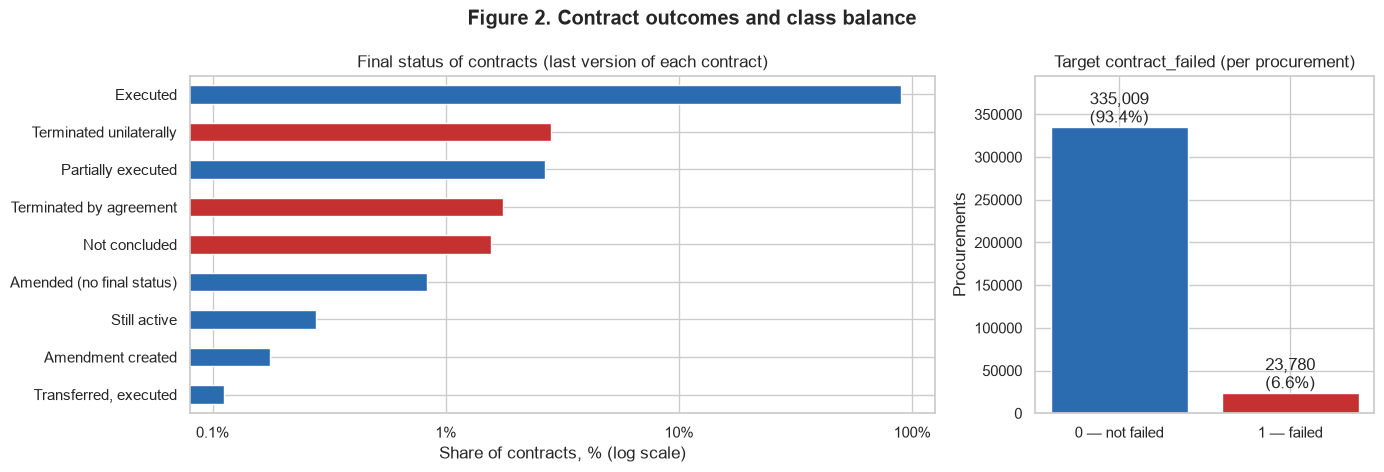

In [22]:
y = df.contract_failed
print(f"Population: {len(df):,} procurements; failed contracts: {y.sum():,} ({y.mean():.2%})")
print(f"Strict definition (without termination by mutual agreement): {df.contract_failed_strict.mean():.2%}")
print(f"Partially executed (kept as 0, reported separately): {df.partially_executed.mean():.2%}")

status = chains.status_ru.value_counts()
names_en = {"Исполнен": "Executed", "Расторгнут в одностороннем порядке": "Terminated unilaterally",
            "Частично исполнен": "Partially executed", "Расторгнут по соглашению сторон": "Terminated by agreement",
            "Не заключен": "Not concluded", "Изменен": "Amended (no final status)", "Действует": "Still active",
            "Создано доп.соглашение": "Amendment created", "Передан.Исполнен": "Transferred, executed"}
status = status.head(9).rename(index=names_en)
failed_labels = {"Terminated unilaterally", "Terminated by agreement", "Not concluded"}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
(status / status.sum() * 100).sort_values().plot.barh(
    ax=ax, color=[PALETTE["fail"] if i in failed_labels else PALETTE["ok"] for i in status.sort_values().index])
ax.set_xscale("log"); ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}%"))
ax.set_title("Final status of contracts (last version of each contract)")
ax.set_xlabel("Share of contracts, % (log scale)"); ax.set_ylabel("")
ax = axes[1]
counts = y.value_counts().sort_index()
ax.bar(["0 — not failed", "1 — failed"], counts.values, color=[PALETTE["ok"], PALETTE["fail"]])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v / len(y):.1%})", ha="center", va="bottom")
ax.set_title("Target contract_failed (per procurement)"); ax.set_ylabel("Procurements"); ax.set_ylim(0, counts.max() * 1.18)
fig.suptitle("Figure 2. Contract outcomes and class balance", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "fig02_target.png", dpi=150); plt.show()

**Interpretation (Figure 2).** About **one procurement in fifteen (6.6 %)** ends with a failed contract. The most
common failure is *unilateral termination* (usually the customer terminating a supplier who does not deliver),
followed by termination by agreement and contracts that were never signed. The classes are **imbalanced 1 : 14**, so
accuracy would be a misleading metric (always predicting "not failed" is already 93 % accurate); the baseline is
evaluated with ROC-AUC, PR-AUC and F1 instead.

*Note:* a pilot sample in the proposal (A1) suggested ≈ 23 %. The full data show the pilot was biased — it came from
one page of the API ordered by id; the full population is the reliable estimate.

### 7.2 Procurement value

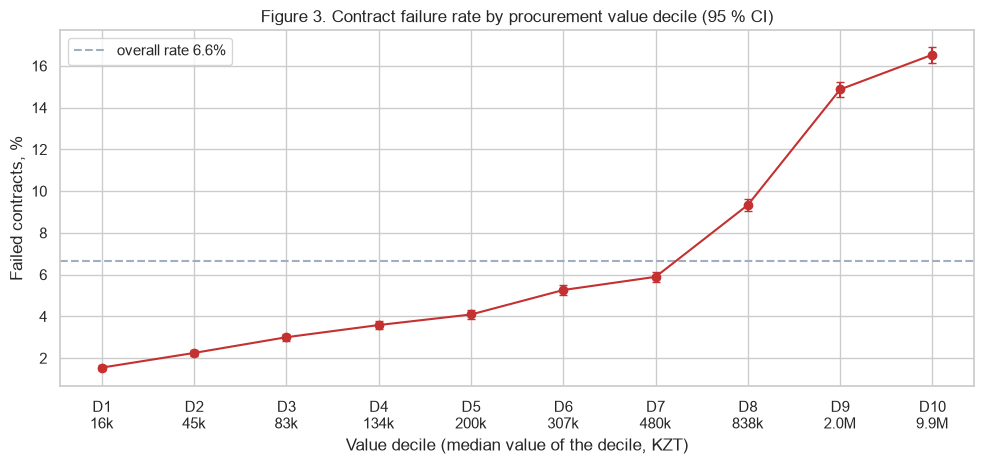

,rate,n,median_value
value_decile,,,
1,0.0154,"38,062.0000","16,000.0000"
2,0.0225,"33,727.0000","45,000.0000"
3,0.0300,"35,864.0000","83,034.5000"
4,0.0358,"35,886.0000","133,928.5700"
5,0.0409,"36,557.0000","200,400.0000"
6,0.0526,"35,237.0000","307,140.0000"
7,0.0589,"36,027.0000","480,000.0000"
8,0.0934,"35,671.0000","838,392.0000"
9,0.1487,"35,879.0000","2,000,000.0000"


In [23]:
def rate_ci(g):
    p = g.mean(); n = len(g); se = np.sqrt(p * (1 - p) / n)
    return pd.Series({"rate": p, "lo": p - 1.96 * se, "hi": p + 1.96 * se, "n": n})

df["value_decile"] = pd.qcut(df.log_total_sum, 10, labels=False) + 1
dec = df.groupby("value_decile").contract_failed.apply(rate_ci).unstack()
dec["median_value"] = df.groupby("value_decile").total_sum.median()

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.errorbar(dec.index, dec.rate * 100, yerr=[(dec.rate - dec.lo) * 100, (dec.hi - dec.rate) * 100],
            marker="o", color=PALETTE["fail"], capsize=3)
ax.axhline(y.mean() * 100, ls="--", color=PALETTE["grey"], label=f"overall rate {y.mean():.1%}")
ax.set_xticks(dec.index)
ax.set_xticklabels([f"D{i}\n{v / 1e3:,.0f}k" if v < 1e6 else f"D{i}\n{v / 1e6:,.1f}M" for i, v in dec.median_value.items()])
ax.set_title("Figure 3. Contract failure rate by procurement value decile (95 % CI)")
ax.set_xlabel("Value decile (median value of the decile, KZT)"); ax.set_ylabel("Failed contracts, %")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "fig03_value.png", dpi=150); plt.show()
dec[["rate", "n", "median_value"]]

**Observation 1 (Figure 3).** Failure risk rises **almost monotonically and tenfold** with procurement value: from
≈ 1.5 % in the cheapest decile (median 16 thousand KZT) to ≈ 16.5 % in the most expensive one (median ≈ 10 million KZT).
The confidence intervals do not overlap between the lowest and highest deciles, so this is not noise. Large contracts
are longer and more complex, give the supplier more room to fail, and make termination worthwhile for the customer.
This supports **H2**.

### 7.3 Procurement method

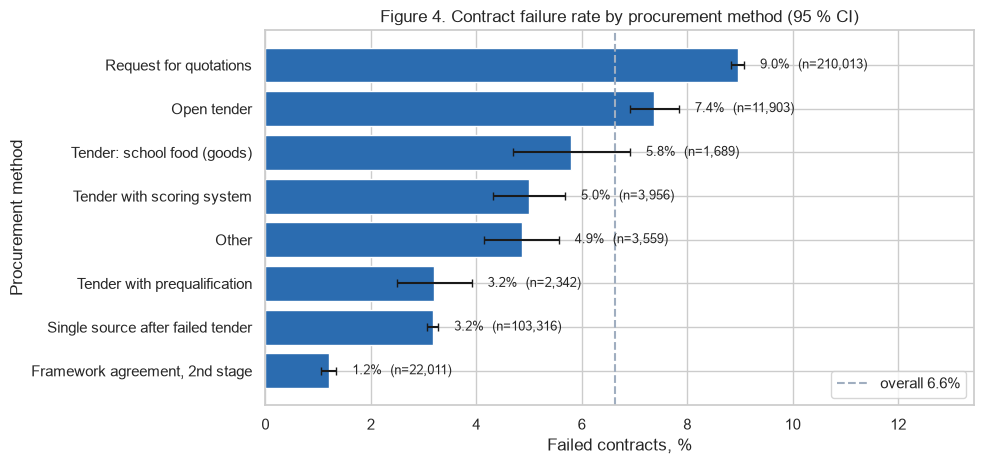

In [24]:
meth = df.groupby("trade_method").contract_failed.apply(rate_ci).unstack().sort_values("rate")
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(meth.index, meth.rate * 100, xerr=[(meth.rate - meth.lo) * 100, (meth.hi - meth.rate) * 100],
        color=PALETTE["ok"], capsize=3)
ax.axvline(y.mean() * 100, ls="--", color=PALETTE["grey"], label=f"overall {y.mean():.1%}")
for i, (r_, hi_, n_) in enumerate(zip(meth.rate, meth.hi, meth.n)):
    ax.text(hi_ * 100 + 0.3, i, f"{r_:.1%}  (n={n_:,.0f})", va="center", fontsize=9)
ax.set_title("Figure 4. Contract failure rate by procurement method (95 % CI)")
ax.set_xlabel("Failed contracts, %"); ax.set_ylabel("Procurement method"); ax.set_xlim(0, meth.rate.max() * 100 * 1.5)
ax.legend(loc="lower right"); plt.tight_layout(); plt.savefig(FIG / "fig04_method.png", dpi=150); plt.show()

**Observation 2 (Figure 4).** The method matters a lot. **Requests for quotations** — the cheapest, fastest procedure
where the lowest price wins automatically — have the highest failure rate (≈ 9 %), while **single-source purchases
after a failed tender** fail only ≈ 3 % of the time and framework-agreement call-offs ≈ 1 %. A plausible mechanism:
automatic lowest-price selection attracts unrealistic offers that the winner later cannot honour, while in a single-source
purchase the terms are negotiated with a supplier who has explicitly agreed to them, and framework call-offs go to
pre-qualified suppliers.

### 7.4 Competition: number of bidders (and Simpson's paradox)

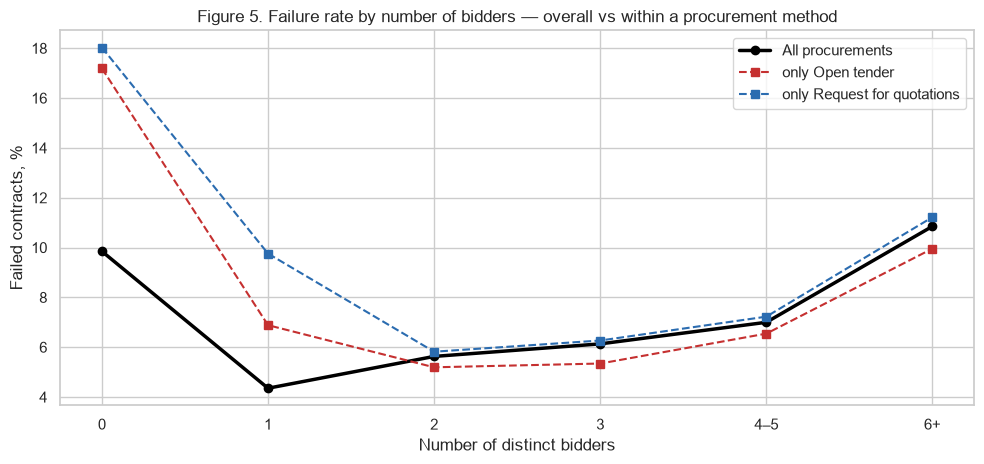

,all,share of single-source in group,Open tender,Request for quotations
bidders_bin,,,,
0,0.0985,0.6208,0.1719,0.1803
1,0.0435,0.4985,0.0688,0.0976
2,0.0563,0.0000,0.0519,0.0582
3,0.0613,0.0000,0.0534,0.0627
4–5,0.0700,0.0000,0.0654,0.0722
6+,0.1085,0.0000,0.0996,0.1122


In [25]:
df["bidders_bin"] = pd.cut(df.n_bidders, [-1, 0, 1, 2, 3, 5, 10_000], labels=["0", "1", "2", "3", "4–5", "6+"])
overall = df.groupby("bidders_bin", observed=True).contract_failed.mean()
by_m = (df[df.trade_method.isin(["Request for quotations", "Open tender"])]
        .groupby(["trade_method", "bidders_bin"], observed=True).contract_failed.mean().unstack(0))
share_ss = df.groupby("bidders_bin", observed=True).trade_method.apply(
    lambda s: (s == "Single source after failed tender").mean())

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(overall.index.astype(str), overall * 100, marker="o", lw=2.5, color="black", label="All procurements")
for m, c in zip(by_m.columns, [PALETTE["fail"], PALETTE["ok"]]):
    ax.plot(by_m.index.astype(str), by_m[m] * 100, marker="s", ls="--", color=c, label=f"only {m}")
ax.set_title("Figure 5. Failure rate by number of bidders — overall vs within a procurement method")
ax.set_xlabel("Number of distinct bidders"); ax.set_ylabel("Failed contracts, %"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "fig05_bidders.png", dpi=150); plt.show()
pd.DataFrame({"all": overall, "share of single-source in group": share_ss}).join(by_m)

**Observation 3 (Figure 5) — Simpson's paradox.** Looking at all procurements together, *one* bidder seems to be the
safest situation (4.4 %). But half of single-bidder procurements are single-source purchases, which are low-risk for the
reason shown in Figure 4. **Within the same method the picture reverses:** for requests for quotations a single bidder
means ≈ 9.8 % failures versus ≈ 5.8 % with two bidders, and the same holds for open tenders. This **supports H1** —
but only once the method is controlled for, which is why the method must enter the model together with competition.

**Observation 4.** The relationship is **U-shaped**: with 6+ bidders the failure rate climbs back to ≈ 11 %. Fierce
competition for lowest-price procedures pushes winners to bid below their real cost (the *winner's curse*), which
later shows up as non-delivery. Procurements with **no recorded offers** but with a contract (mostly single-source)
have the highest rate inside each method (≈ 17–18 %).

### 7.5 Subject of purchase and region

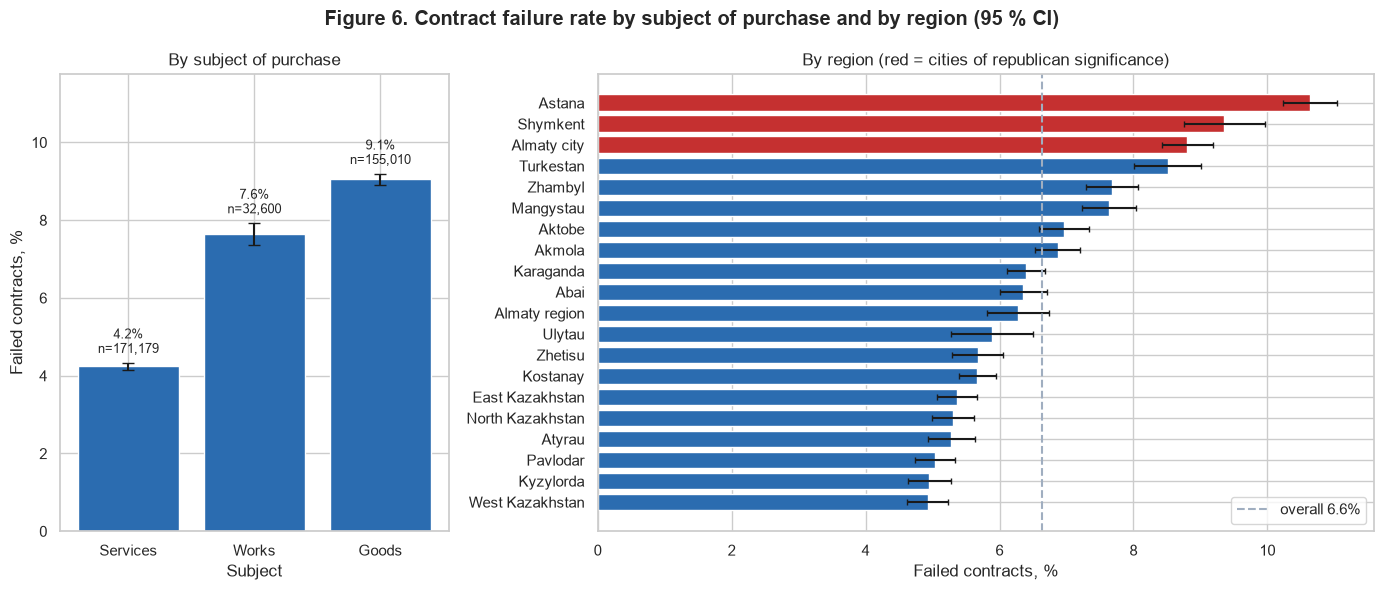

In [26]:
subj = df.groupby("subject_type").contract_failed.apply(rate_ci).unstack().sort_values("rate")
reg = df[df.region != "Unknown"].groupby("region").contract_failed.apply(rate_ci).unstack().sort_values("rate")

fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 2]})
ax = axes[0]
ax.bar(subj.index, subj.rate * 100, yerr=[(subj.rate - subj.lo) * 100, (subj.hi - subj.rate) * 100],
       color=PALETTE["ok"], capsize=4)
for i, (r_, hi_, n_) in enumerate(zip(subj.rate, subj.hi, subj.n)):
    ax.text(i, hi_ * 100 + 0.25, f"{r_:.1%}\nn={n_:,.0f}", ha="center", fontsize=9)
ax.set_title("By subject of purchase"); ax.set_xlabel("Subject"); ax.set_ylabel("Failed contracts, %")
ax.set_ylim(0, subj.rate.max() * 100 * 1.3)
ax = axes[1]
colors = [PALETTE["fail"] if r_ in ("Astana", "Almaty city", "Shymkent") else PALETTE["ok"] for r_ in reg.index]
ax.barh(reg.index, reg.rate * 100, xerr=[(reg.rate - reg.lo) * 100, (reg.hi - reg.rate) * 100], color=colors, capsize=2)
ax.axvline(y.mean() * 100, ls="--", color=PALETTE["grey"], label=f"overall {y.mean():.1%}")
ax.set_title("By region (red = cities of republican significance)"); ax.set_xlabel("Failed contracts, %"); ax.set_ylabel("")
ax.legend(loc="lower right")
fig.suptitle("Figure 6. Contract failure rate by subject of purchase and by region (95 % CI)", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "fig06_subject_region.png", dpi=150); plt.show()

**Observation 5 (Figure 6, left).** **Goods** fail more than twice as often as **services** (≈ 9.1 % vs 4.2 %), with
**works** in between (7.6 %). Services such as utilities, internet or cleaning are typically delivered by the same
established providers every year, whereas goods depend on supply chains and price changes between bid and delivery.

**Observation 6 (Figure 6, right).** Regional differences are large and systematic: the three **cities of republican
significance** — Astana (10.6 %), Shymkent (9.4 %) and Almaty (8.8 %) — have the highest failure rates, about twice
the rate of West Kazakhstan, Kyzylorda or Pavlodar (≈ 5 %). Big cities have more suppliers and more competitive,
lower-priced bidding, which is consistent with Observation 4. Region is therefore a useful feature (RQ2).

### 7.6 Stability over time

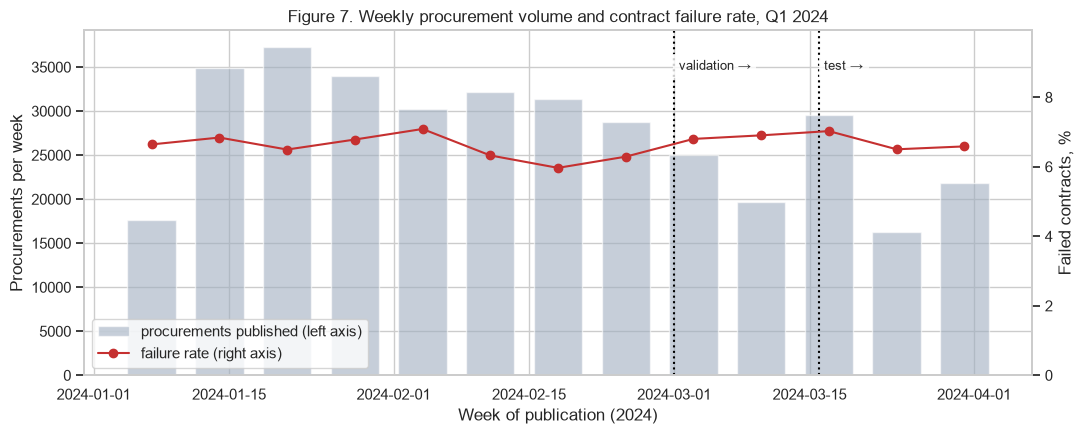

             mean    size
publish_dt               
1          0.0672  141061
2          0.0642  125233
3          0.0676   92495


In [27]:
wk = df.set_index("publish_dt").resample("W").agg(n=("contract_failed", "size"), rate=("contract_failed", "mean"))
wk = wk[wk.n > 1000]
fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.bar(wk.index, wk.n, width=5, color=PALETTE["grey"], alpha=.6, label="procurements published (left axis)")
ax1.set_ylabel("Procurements per week"); ax1.set_xlabel("Week of publication (2024)")
ax2 = ax1.twinx()
ax2.plot(wk.index, wk.rate * 100, marker="o", color=PALETTE["fail"], label="failure rate (right axis)")
ax2.set_ylabel("Failed contracts, %"); ax2.set_ylim(0, wk.rate.max() * 100 * 1.4); ax2.grid(False)
for d, lab in [("2024-03-01", "validation →"), ("2024-03-16", "test →")]:
    ax1.axvline(pd.Timestamp(d), color="black", ls=":")
    ax1.text(pd.Timestamp(d) + pd.Timedelta(days=0.5), wk.n.max() * 0.93, lab, fontsize=9,
             bbox=dict(facecolor="white", edgecolor="none", alpha=.8))
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="lower left")
ax1.set_title("Figure 7. Weekly procurement volume and contract failure rate, Q1 2024")
plt.tight_layout(); plt.savefig(FIG / "fig07_time.png", dpi=150); plt.show()
print(df.groupby(df.publish_dt.dt.month).contract_failed.agg(["mean", "size"]))

**Observation 7 (Figure 7).** Volume is highest in January (start of the budget year) and declines towards March,
but the **failure rate is stable at 6.4–6.8 % per month** with no trend. The outcome-generating process does not drift
within the quarter, which makes a chronological split (§10) a fair test: a model trained on January–February is
evaluated on a period with the same base rate but unseen procurements.

### 7.7 Relationships between numeric features

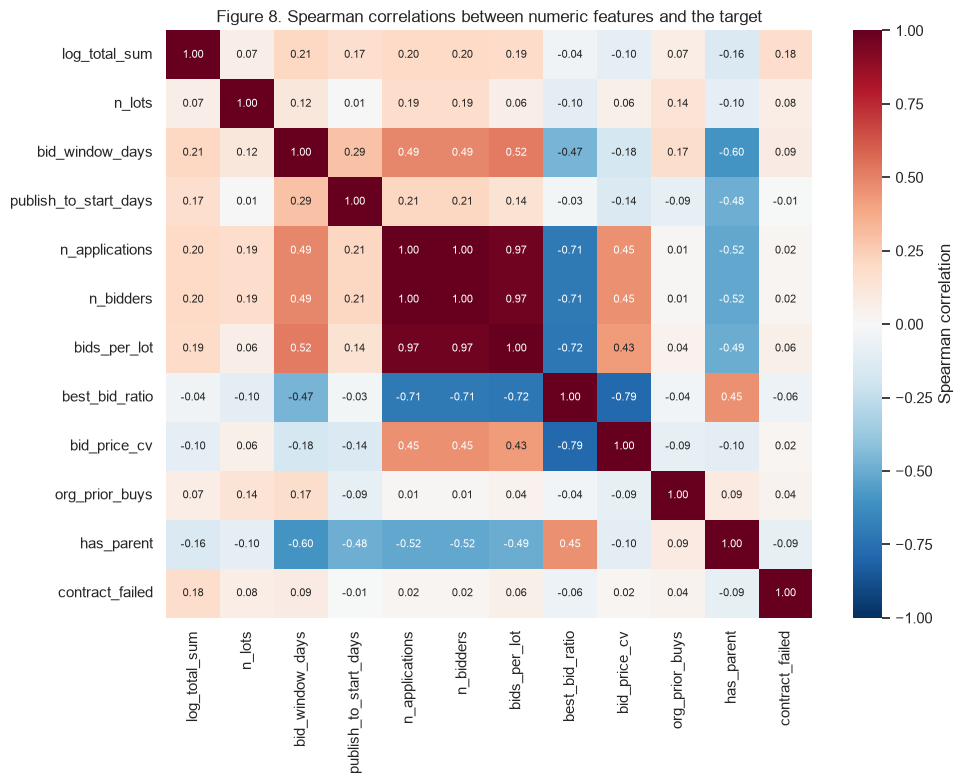

In [28]:
num_cols = ["log_total_sum", "n_lots", "bid_window_days", "publish_to_start_days", "n_applications", "n_bidders",
            "bids_per_lot", "best_bid_ratio", "bid_price_cv", "org_prior_buys", "has_parent", "contract_failed"]
corr = df[num_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax,
            cbar_kws={"label": "Spearman correlation"}, annot_kws={"size": 8})
ax.set_title("Figure 8. Spearman correlations between numeric features and the target")
plt.tight_layout(); plt.savefig(FIG / "fig08_corr.png", dpi=150); plt.show()

**Observation 8 (Figure 8).** No single numeric feature is strongly correlated with the target (largest: procurement
value, ρ ≈ 0.18) — failure is driven by *combinations* of factors (value × method × competition), which motivates a
multivariate model rather than a single rule. The competition features form a tightly linked block: `n_applications`
and `n_bidders` are identical in rank (ρ = 1.00 — one application per bidder), `bids_per_lot` is almost the same
(ρ = 0.97), and more bidders go together with deeper discounts (`best_bid_ratio`, ρ = −0.71). `has_parent` is
essentially a marker of single-source purchases (95 % of procurements with a parent link use that method).
`n_applications` is therefore dropped from the feature set, and the remaining collinearity has to be kept in mind
when reading linear-model coefficients.

## 9. Features (X), target (y) and data-leakage audit

**Prediction moment.** The model is meant to be used *right after the winner is selected* — when the procurement,
its lots and all offers are known, but the contract has not been executed yet.

**Target `y = contract_failed`.** 1 if any contract that resulted from the procurement ended (last version of the
contract chain) with status *Terminated unilaterally* (340), *Terminated by mutual agreement* (350), *Not concluded*
(330), *Awaiting termination* (345) or their "transferred" variants (462, 463); 0 if all its contracts were executed,
are active or amended without termination. *Partially executed* (375, 3.2 %) is ambiguous and is kept as 0; a strict
target (without terminations by agreement, 4.5 %) is stored for sensitivity analysis.

*Why this target:* it is an **observed, independently recorded event** with a direct cost for the state. The earlier
engineering prototype (Tender Radar) labelled "risk" with 31 hand-written rules; training a model on such labels only
teaches it to reproduce the rules (circular). Here the rules' ideas enter as **features**, and the outcome is real.

In [29]:
FEATURES = {
    "log_total_sum": ("numeric", "↑ larger contracts fail more often (Fig. 3)"),
    "n_lots": ("numeric", "↑ more lots = more complex delivery"),
    "bid_window_days": ("numeric", "± very short windows limit competition; long ones belong to complex tenders"),
    "publish_to_start_days": ("numeric", "± preparation time before applications open"),
    "n_bidders": ("numeric", "U-shaped: 1 bidder and 6+ bidders are riskier (Fig. 5)"),
    "bids_per_lot": ("numeric", "competition per lot"),
    "best_bid_ratio": ("numeric", "↓ deep discounts may signal an unrealistically low price"),
    "bid_price_cv": ("numeric", "dispersion of offers; high = uncertain market price"),
    "org_prior_buys": ("numeric", "experience of the organiser (count of its earlier announcements only)"),
    "no_bids": ("binary", "↑ contract without recorded offers (≈17 % failure inside a method)"),
    "single_organizer": ("binary", "centralised purchasing"),
    "construction": ("binary", "construction works are long and complex"),
    "light_industry": ("binary", "domestic-producer support regime"),
    "disabled_org": ("binary", "purchases reserved for organisations of disabled people"),
    "any_dumping": ("binary", "↓ anti-dumping provisions protect against unrealistic prices"),
    "any_design_docs": ("binary", "design documentation required"),
    "any_consulting": ("binary", "consulting services"),
    "trade_method": ("categorical", "strong effect: quotations 9 % vs framework 1 % (Fig. 4)"),
    "subject_type": ("categorical", "goods 9 % vs services 4 % (Fig. 6)"),
    "region": ("categorical", "big cities ≈ 2× the rate of some regions (Fig. 6)"),
}
X_COLS = list(FEATURES)
NUM = [c for c, (t, _) in FEATURES.items() if t == "numeric"]
BIN = [c for c, (t, _) in FEATURES.items() if t == "binary"]
CAT = [c for c, (t, _) in FEATURES.items() if t == "categorical"]
TARGET = "contract_failed"
pd.DataFrame([(c, t, e) for c, (t, e) in FEATURES.items()], columns=["feature", "type", "expected influence on y"])

,feature,type,expected influence on y
0,log_total_sum,numeric,↑ larger contracts fail more often (Fig. 3)
1,n_lots,numeric,↑ more lots = more complex delivery
2,bid_window_days,numeric,± very short windows limit competition; long ones belong to complex tenders
3,publish_to_start_days,numeric,± preparation time before applications open
4,n_bidders,numeric,U-shaped: 1 bidder and 6+ bidders are riskier (Fig. 5)
5,bids_per_lot,numeric,competition per lot
6,best_bid_ratio,numeric,↓ deep discounts may signal an unrealistically low price
7,bid_price_cv,numeric,dispersion of offers; high = uncertain market price
8,org_prior_buys,numeric,experience of the organiser (count of its earlier announcements only)
9,no_bids,binary,↑ contract without recorded offers (≈17 % failure inside a method)


`lot_names` (concatenated lot names) is kept in the table for the **text branch** of the project (TF-IDF in the
midterm, transformer fine-tuning in A3). It is catalogue-like text: only ≈2–3 % of lot names are unique, so it behaves
like a high-cardinality "what is bought" category.

### 9.1 Data-leakage audit

| Candidate information | Known at prediction time? | Decision |
|---|---|---|
| Contract status, `faktSum`, `faktExecDate`, `contractEndDate` | no — this *is* the outcome | used only to build `y` |
| `signDate`, `contractSum` | partly — set at signing; missing exactly for not-concluded contracts | excluded (missingness reveals the label) |
| `trd_buy.refBuyStatusId` (procurement status) | final state, may be updated after the contract fails | excluded |
| `itogiDatePublic` (results date) | may be re-published after the winner refuses to sign | excluded |
| `lastUpdateDate`, `indexDate` | system timestamps updated long after the award | excluded |
| RNU register (supplier blacklisted) | inclusion happens *after* termination (§5.5) | excluded — consequence of the outcome |
| Past failure rate of the organiser / supplier | would need outcomes of earlier contracts that were still running | excluded; only *activity* counts (`org_prior_buys`) from publication dates |
| Imputation / scaling statistics | computed on the full table they would leak | fitted on the training split only (pipeline, §11) |

In [30]:
leaky = {"faktSum", "faktExecDate", "signDate", "contractSum", "refBuyStatusId", "itogiDatePublic",
         "lastUpdateDate", "indexDate", "status_id", "supplierBiin"}
assert not leaky & set(X_COLS), "a leaking column slipped into the features"
assert TARGET not in X_COLS
print(f"X: {len(X_COLS)} features ({len(NUM)} numeric, {len(BIN)} binary, {len(CAT)} categorical); y: {TARGET}")

X: 20 features (9 numeric, 8 binary, 3 categorical); y: contract_failed


## 10. Train / validation / test split

The data are **time-ordered**, and the model will always be applied to *future* procurements, so the split is
**chronological — no random shuffling**. A random split would let the model see procurements of the same weeks,
organisers and market prices in training and testing, and would overestimate its quality.

| Split | Publication period | Role |
|---|---|---|
| train | 1 Jan – 29 Feb 2024 | fit the model |
| validation | 1 – 15 Mar 2024 | choose model / threshold |
| test | 16 – 31 Mar 2024 | final, untouched evaluation |

Calendar boundaries keep the split interpretable; they give ≈ 74 / 15 / 11 %, close to the usual 70 / 15 / 15.
**Stratification is not used** — it would require shuffling across time; instead we check below that the positive
rate is practically the same in every split (Figure 7 already showed no drift).

In [31]:
df["split"] = np.select([df.publish_dt < "2024-03-01", df.publish_dt < "2024-03-16"], ["train", "val"], "test")
summary = df.groupby("split").agg(rows=("id", "size"), failed=(TARGET, "sum"), failure_rate=(TARGET, "mean"),
                                  first=("publish_dt", "min"), last=("publish_dt", "max")).loc[["train", "val", "test"]]
summary["share"] = summary.rows / summary.rows.sum()
assert summary["last"].iloc[0] < summary["first"].iloc[1] and summary["last"].iloc[1] < summary["first"].iloc[2]
summary

,rows,failed,failure_rate,first,last,share
split,,,,,,
train,266294,17530,0.0658,2024-01-01 01:46:32,2024-02-29 22:06:38,0.7422
val,53514,3683,0.0688,2024-03-01 03:51:48,2024-03-15 23:56:38,0.1492
test,38981,2567,0.0659,2024-03-16 00:04:29,2024-03-31 23:59:44,0.1086


In [32]:
keep = ["id", "publish_dt", "split", TARGET, "contract_failed_strict", "partially_executed", "lot_names"] + X_COLS
df[keep].to_parquet(PROCESSED / "model_table.parquet", index=False)
print(f"saved data/processed/model_table.parquet: {len(df):,} rows × {len(keep)} columns")

saved data/processed/model_table.parquet: 358,789 rows × 27 columns


## 11. Baseline model

A first reference point for the midterm: a **majority/prior classifier** (what we get without any model) and a
**logistic regression** with class weighting. All preprocessing (median imputation with missing-indicators, scaling,
one-hot encoding) is inside a scikit-learn `Pipeline`, so it is fitted on the training split only.

In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, precision_recall_curve, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

tr, va, te = (df[df.split == s] for s in ("train", "val", "test"))
pre = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), NUM),
    ("bin", "passthrough", BIN),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), CAT),
])
logreg = make_pipeline(pre, LogisticRegression(class_weight="balanced", max_iter=2000))
logreg.fit(tr[X_COLS], tr[TARGET])
dummy = DummyClassifier(strategy="prior").fit(tr[X_COLS], tr[TARGET])

# decision threshold chosen on validation (max F1), then applied unchanged to test
p_val = logreg.predict_proba(va[X_COLS])[:, 1]
prec, rec, thr = precision_recall_curve(va[TARGET], p_val)
threshold = thr[np.argmax((2 * prec * rec / (prec + rec + 1e-12))[:-1])]

def evaluate(model, part, name):
    p = model.predict_proba(part[X_COLS])[:, 1]
    top = np.argsort(-p)[: int(len(p) * 0.01)]
    return {"model": name, "ROC-AUC": roc_auc_score(part[TARGET], p),
            "PR-AUC": average_precision_score(part[TARGET], p),
            "F1": f1_score(part[TARGET], p >= threshold) if name.startswith("Logistic") else 0.0,
            "precision@top1%": part[TARGET].iloc[top].mean(), "base rate": part[TARGET].mean()}

res = pd.DataFrame([evaluate(m, part, f"{n} — {s}") for s, part in (("validation", va), ("test", te))
                    for n, m in (("Prior (no model)", dummy), ("Logistic regression", logreg))])
print(f"decision threshold (tuned on validation): {threshold:.3f}")
res.round(3)

decision threshold (tuned on validation): 0.715


,model,ROC-AUC,PR-AUC,F1,precision@top1%,base rate
0,Prior (no model) — validation,0.5000,0.0690,0.0000,0.0520,0.0690
1,Logistic regression — validation,0.7940,0.2900,0.3430,0.5760,0.0690
2,Prior (no model) — test,0.5000,0.0660,0.0000,0.0570,0.0660
3,Logistic regression — test,0.7920,0.2620,0.3240,0.5040,0.0660


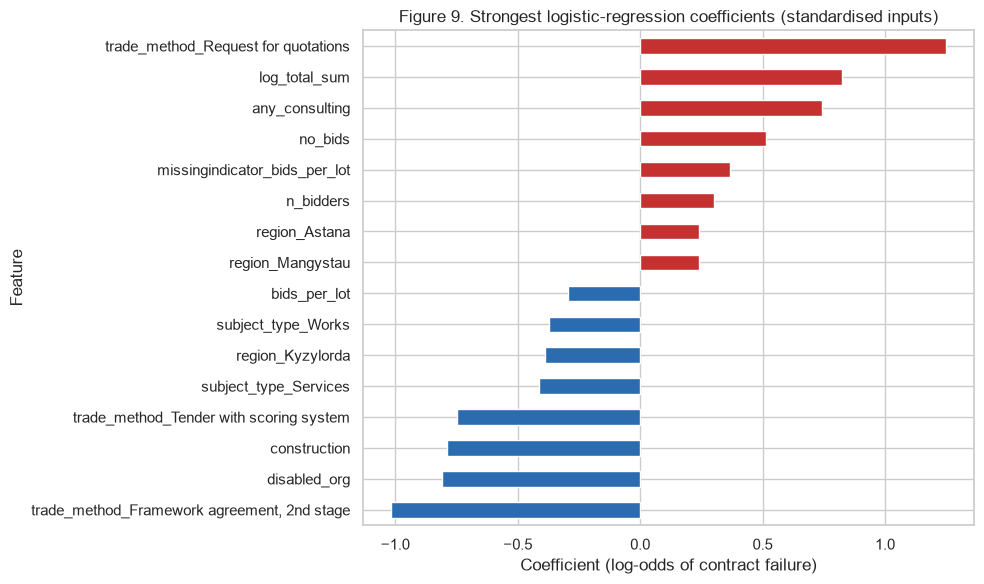

In [34]:
coef = pd.Series(logreg[-1].coef_[0], index=logreg[0].get_feature_names_out())
top = pd.concat([coef.nlargest(8), coef.nsmallest(8)]).sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
top.plot.barh(ax=ax, color=[PALETTE["fail"] if v > 0 else PALETTE["ok"] for v in top])
ax.set_title("Figure 9. Strongest logistic-regression coefficients (standardised inputs)")
ax.set_xlabel("Coefficient (log-odds of contract failure)"); ax.set_ylabel("Feature")
ax.set_yticklabels([t.get_text().split("__")[-1] for t in ax.get_yticklabels()])
plt.tight_layout(); plt.savefig(FIG / "fig09_coef.png", dpi=150); plt.show()

**Baseline result.** On the untouched **test** period (16–31 March) the logistic regression reaches
**ROC-AUC ≈ 0.79** and **PR-AUC ≈ 0.27** — about **four times the base rate** of 6.6 % — while the prior classifier
has ROC-AUC 0.5 by construction. Among the 1 % of procurements the model ranks as most risky, **more than half**
actually failed (≈ 7.6× the base rate). Validation and test scores are close, so the model is not overfitted to a
particular period. The coefficients (Figure 9) agree with the EDA: the request-for-quotations method, procurement value
and the absence of recorded offers increase the risk; framework-agreement call-offs, scoring-system tenders and
services/works (compared with goods) decrease it. The opposite signs of `n_bidders` (+) and `bids_per_lot` (−) are a
symptom of their collinearity (Observation 8) and of the U-shaped effect that a linear term cannot represent — a
concrete argument for the tree-based models planned for the midterm, together with the text of lot names.

## 12. Scientific interpretation and conclusions

**RQ1 — method and competition.** The procurement method is one of the strongest factors: automatic lowest-price
*requests for quotations* fail about three times as often as single-source purchases and seven times as often as
framework call-offs. **H1 is supported, but only after controlling for the method:** naively, single-bidder procurements
look safest (Simpson's paradox), yet within the same method one bidder is riskier than two or three. The relationship
with competition is U-shaped — very intense competition (6+ bidders) is risky again, consistent with the *winner's
curse* in lowest-price auctions. For practice this means that "single bidder" — the most popular red flag in the
procurement-integrity literature — should be interpreted relative to the method, and that extreme price competition
deserves equal attention.

**RQ2 — size, type, location.** **H2 is supported:** the failure rate grows tenfold from the cheapest to the most
expensive decile. Goods fail twice as often as services, and the three largest cities have about twice the failure rate
of several regions. Value, subject and region are therefore informative, and an auditor's limited capacity should
naturally be weighted towards large, goods-type, big-city procurements.

**RQ3 — predictability.** **H3 is supported:** a simple logistic regression trained on January–February ranks March
procurements with ROC-AUC ≈ 0.79 and a PR-AUC four times the base rate, and half of its top-1 % list are real
failures. Information available at award time is thus genuinely predictive of contract failure.

**Limitations.**
1. One quarter of one year: seasonality (e.g. year-end purchases) is not represented.
2. The label mixes failures caused by suppliers and decisions of customers (*termination by agreement*); the strict
   variant is stored for a sensitivity check.
3. Supplier and organiser *track records* cannot be used without leakage because the outcome dates of earlier contracts
   are not observed; the RNU register is a consequence of failure, not a predictor.
4. Offers are missing for some procurements (16 % without priced offers) and price units are occasionally inconsistent.
5. The analysis is associational — the observed effects (e.g. of the method) are not causal.

**Next steps (midterm / A3).** Tree-based models (Random Forest, gradient boosting) to capture the interactions found in
the EDA (value × method × competition); TF-IDF and a fine-tuned multilingual transformer on lot names; threshold and
calibration analysis; comparison with the 31 rule-based indicators of the earlier Tender Radar prototype.